# 用 RGCN 预测药物-疾病 Indication 关系（PrimeKG）


In [1]:
import sys, os, time
sys.path.insert(0, os.path.abspath("../src"))
from tqdm import tqdm
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import matplotlib as mpl
from sklearn.metrics import roc_auc_score, average_precision_score

mpl.rcParams["font.sans-serif"] = ["PingFang SC", "Heiti SC", "Arial Unicode MS", "DejaVu Sans"]
mpl.rcParams["axes.unicode_minus"] = False

import prepare_data
import importlib.util
_spec = importlib.util.spec_from_file_location("model", os.path.abspath("../src/1.py"))
sys.modules["model"] = importlib.util.module_from_spec(_spec); _spec.loader.exec_module(sys.modules["model"])
from model import RGCNLinkPredictor
from train import split_edges, pair_codes, sample_negatives, evaluate, ranking_eval

SEED = 0
torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("torch:", torch.__version__)
print("device:", device)

/opt/homebrew/Caskroom/miniforge/base/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch: 2.13.0
device: mps


In [2]:
KG_CSV = "../data/raw/kg.csv"
df = prepare_data.load_filtered(KG_CSV)

print(df["relation"].value_counts())

Reading ../data/raw/kg.csv ...
Kept 873054 rows across relations: {'protein_protein': 642150, 'disease_protein': 160822, 'drug_protein': 51306, 'indication': 18776, 'contraindication': 0, 'drug_drug': 0, 'off-label use': 0, 'phenotype_phenotype': 0, 'phenotype_protein': 0, 'disease_phenotype_negative': 0, 'disease_phenotype_positive': 0, 'disease_disease': 0, 'drug_effect': 0, 'bioprocess_bioprocess': 0, 'molfunc_molfunc': 0, 'cellcomp_cellcomp': 0, 'molfunc_protein': 0, 'cellcomp_protein': 0, 'bioprocess_protein': 0, 'exposure_bioprocess': 0, 'exposure_cellcomp': 0, 'exposure_disease': 0, 'exposure_exposure': 0, 'exposure_molfunc': 0, 'exposure_protein': 0, 'pathway_pathway': 0, 'pathway_protein': 0, 'anatomy_anatomy': 0, 'anatomy_protein_present': 0, 'anatomy_protein_absent': 0}
relation
protein_protein               642150
disease_protein               160822
drug_protein                   51306
indication                     18776
contraindication                   0
drug_drug     

## 1. 原始数据探查（PrimeKG `kg.csv`）

In [3]:
# 每种关系抽样看一下原始样子
for rel in prepare_data.MP_RELATIONS + [prepare_data.TARGET_RELATION]:
    print(f"\n--- {rel} ---")
    display(df[df["relation"] == rel].head(3)[["relation", "x_index", "x_type", "y_index", "y_type"]])


--- drug_protein ---


,relation,x_index,x_type,y_index,y_type
321075,drug_protein,14012,drug,7183,gene/protein
321076,drug_protein,14012,drug,8256,gene/protein
321077,drug_protein,14013,drug,4107,gene/protein



--- protein_protein ---


,relation,x_index,x_type,y_index,y_type
0,protein_protein,0,gene/protein,8889,gene/protein
1,protein_protein,1,gene/protein,2798,gene/protein
2,protein_protein,2,gene/protein,5646,gene/protein



--- disease_protein ---


,relation,x_index,x_type,y_index,y_type
356116,disease_protein,7097,gene/protein,28313,disease
356117,disease_protein,2174,gene/protein,28313,disease
356118,disease_protein,8038,gene/protein,28313,disease



--- indication ---


,relation,x_index,x_type,y_index,y_type
346728,indication,16687,drug,33577,disease
346729,indication,16687,drug,36035,disease
346730,indication,20297,drug,33577,disease


In [4]:
ind = df[df["relation"] == "indication"]
print(ind[["x_type", "y_type"]].value_counts())

x_type   y_type            
drug     disease               9388
disease  drug                  9388
drug     drug                     0
         gene/protein             0
         effect/phenotype         0
                               ... 
anatomy  molecular_function       0
         cellular_component       0
         exposure                 0
         pathway                  0
         anatomy                  0
Name: count, Length: 100, dtype: int64


## 2. 构建图

In [5]:
PROCESSED_DIR = "../data/processed"

prepare_data.build_graph(df, PROCESSED_DIR)

data = torch.load(os.path.join(PROCESSED_DIR, "graph.pt"), weights_only=False)

edge_index = data["edge_index"]
edge_type = data["edge_type"]
label_edge_index = data["label_edge_index"]
drug_ids = data["drug_ids"]
disease_ids = data["disease_ids"]
num_nodes = data["num_nodes"]
num_relations = data["num_relations"]

print(f"\nnumber of nodes: {num_nodes} (drug={len(drug_ids)}, disease={len(disease_ids)})")
print(f"edges of indication）: {label_edge_index.shape[1]}")

Total nodes in filtered graph: 31704
  gene/protein: 19093
  drug: 6593
  disease: 6018
  effect/phenotype: 0
  biological_process: 0
  molecular_function: 0
  cellular_component: 0
  exposure: 0
  pathway: 0
  anatomy: 0
Message-passing edges (both directions, as stored in PrimeKG): 854278
Unique indication (drug-disease) edges: 9388
Saved graph to ../data/processed/graph.pt

number of nodes: 31704 (drug=6593, disease=6018)
edges of indication）: 9388


## 3. 模型定义

In [6]:
HIDDEN_DIM = 128
OUT_DIM = 64
NUM_BASES = None  # 3 种关系，不用 basis 分解
NUM_LAYERS = 2
DROPOUT = 0.2

model = RGCNLinkPredictor(
    num_nodes, num_relations,
    hidden_dim=HIDDEN_DIM, out_dim=OUT_DIM,
    num_bases=NUM_BASES, num_layers=NUM_LAYERS, dropout=DROPOUT,
).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"\n参数总量: {n_params:,}")

RGCNLinkPredictor(
  (encoder): RGCNEncoder(
    (node_emb): Embedding(31704, 128)
    (convs): ModuleList(
      (0): RGCNConv(128, 128, num_relations=3)
      (1): RGCNConv(128, 64, num_relations=3)
    )
  )
  (decoder): DistMultDecoder(
    (rel_emb): Embedding(1, 64)
  )
)

参数总量: 4,156,672


## 4. 训练

In [14]:
EPOCHS = 200
LR = 1e-2
WEIGHT_DECAY = 1e-5
NEG_RATIO = 1
CKPT_PATH = "../checkpoints/rgcn_indication.pt"
os.makedirs(os.path.dirname(CKPT_PATH), exist_ok=True)

train_edges, val_edges, test_edges = split_edges(label_edge_index, seed=SEED)
print(f"indication -> train {train_edges.shape[1]}, val {val_edges.shape[1]}, test {test_edges.shape[1]}")

train_neg_pool = train_edges[1].unique()
eval_neg_pool = label_edge_index[1].unique()
train_exclude = pair_codes(train_edges, num_nodes)
all_exclude = pair_codes(label_edge_index, num_nodes)
neg_gen = torch.Generator().manual_seed(SEED)
print(f"negative samples -> train {len(train_neg_pool)}, eval {len(eval_neg_pool)}（all disease {len(disease_ids)}）")

optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
edge_index_dev = edge_index.to(device)
edge_type_dev = edge_type.to(device)

history = {"epoch": [], "loss": [], "val_auc": [], "val_ap": []}
best_val_auc = 0.0

t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    model.train()
    optimizer.zero_grad()

    z = model.encode(edge_index_dev, edge_type_dev)

    neg_edges = sample_negatives(train_edges, train_neg_pool, train_edges.shape[1] * NEG_RATIO,
                                 num_nodes, exclude_codes=train_exclude, generator=neg_gen)
    pos_score = model.decode(z, train_edges[0].to(device), train_edges[1].to(device))
    neg_score = model.decode(z, neg_edges[0].to(device), neg_edges[1].to(device))

    scores = torch.cat([pos_score, neg_score])
    labels = torch.cat([torch.ones_like(pos_score), torch.zeros_like(neg_score)])
    loss = F.binary_cross_entropy_with_logits(scores, labels)

    loss.backward()
    optimizer.step()

    if epoch % 5 == 0 or epoch == EPOCHS:
        val_auc, val_ap = evaluate(model, edge_index, edge_type, val_edges, eval_neg_pool,
                                    all_exclude, num_nodes, device)
        history["epoch"].append(epoch)
        history["loss"].append(loss.item())
        history["val_auc"].append(val_auc)
        history["val_ap"].append(val_ap)
        print(f"Epoch {epoch:03d} | loss {loss.item():.4f} | val AUC {val_auc:.4f} | val AP {val_ap:.4f}")
        if val_auc > best_val_auc:
            best_val_auc = val_auc
            torch.save(model.state_dict(), CKPT_PATH)

print(f"\ntime: {time.time()-t0:.1f}s, best AUC: {best_val_auc:.4f}")

indication -> train 7512, val 938, test 938
negative samples -> train 1268, eval 1363（all disease 6018）
Epoch 005 | loss 0.4026 | val AUC 0.9242 | val AP 0.9192
Epoch 010 | loss 0.3340 | val AUC 0.9062 | val AP 0.8937
Epoch 015 | loss 0.3325 | val AUC 0.9164 | val AP 0.9185
Epoch 020 | loss 0.2402 | val AUC 0.9318 | val AP 0.9354
Epoch 025 | loss 0.2056 | val AUC 0.9398 | val AP 0.9428
Epoch 030 | loss 0.1619 | val AUC 0.9490 | val AP 0.9518
Epoch 035 | loss 0.1452 | val AUC 0.9544 | val AP 0.9583
Epoch 040 | loss 0.1243 | val AUC 0.9570 | val AP 0.9600
Epoch 045 | loss 0.1143 | val AUC 0.9595 | val AP 0.9638
Epoch 050 | loss 0.1166 | val AUC 0.9584 | val AP 0.9616
Epoch 055 | loss 0.1062 | val AUC 0.9594 | val AP 0.9628
Epoch 060 | loss 0.1046 | val AUC 0.9597 | val AP 0.9629
Epoch 065 | loss 0.0956 | val AUC 0.9602 | val AP 0.9624
Epoch 070 | loss 0.0974 | val AUC 0.9600 | val AP 0.9621
Epoch 075 | loss 0.0877 | val AUC 0.9608 | val AP 0.9624
Epoch 080 | loss 0.0847 | val AUC 0.9609 

## 5. 训练曲线

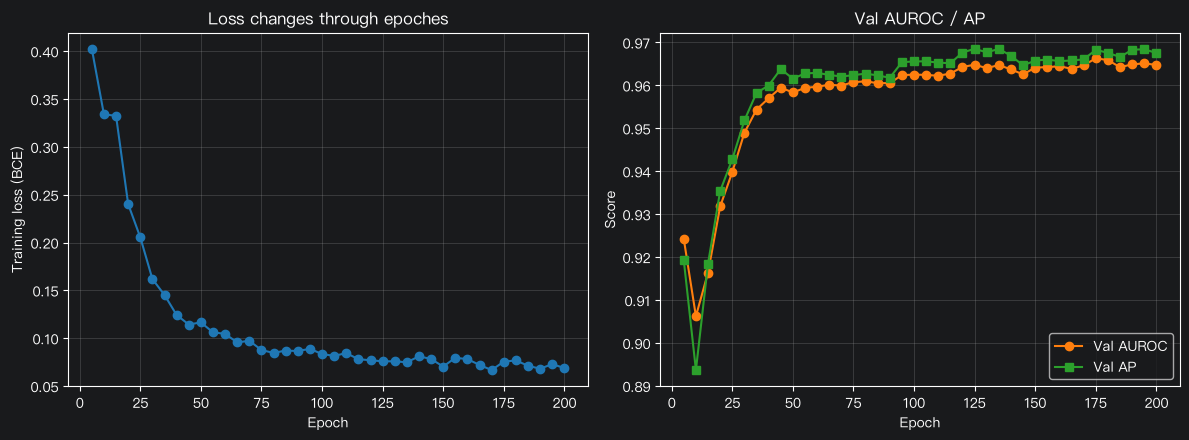

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(history["epoch"], history["loss"], marker="o", color="tab:blue")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Training loss (BCE)")
axes[0].set_title("Loss changes through epoches")
axes[0].grid(alpha=0.3)

axes[1].plot(history["epoch"], history["val_auc"], marker="o", label="Val AUROC", color="tab:orange")
axes[1].plot(history["epoch"], history["val_ap"], marker="s", label="Val AP", color="tab:green")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].set_title("Val AUROC / AP")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("../outputs/training_curves.png", dpi=150)
plt.show()

## 6. 测试集最终评估

In [16]:
model.load_state_dict(torch.load(CKPT_PATH, weights_only=True))

test_auc, test_ap = evaluate(model, edge_index, edge_type, test_edges, eval_neg_pool,
                               all_exclude, num_nodes, device, seed=123)
print(f"Test AUROC: {test_auc:.4f}")
print(f"Test AP:    {test_ap:.4f}")

all_pos = torch.cat([train_edges, val_edges, test_edges], dim=1)
ranking = ranking_eval(model, edge_index, edge_type, test_edges, disease_ids, all_pos, device)
print("\nTest Filter:")
for k, v in ranking.items():
    print(f"  {k}: {v:.4f}")

Test AUROC: 0.9652
Test AP:    0.9675

Test Filter:
  MRR: 0.2387
  Hits@1: 0.1290
  Hits@3: 0.2719
  Hits@10: 0.4638


,metric,value
0,Test AUROC,0.965230
1,Test AP,0.967463
2,MRR,0.238662
3,Hits@1,0.128998
4,Hits@3,0.271855
5,Hits@10,0.463753


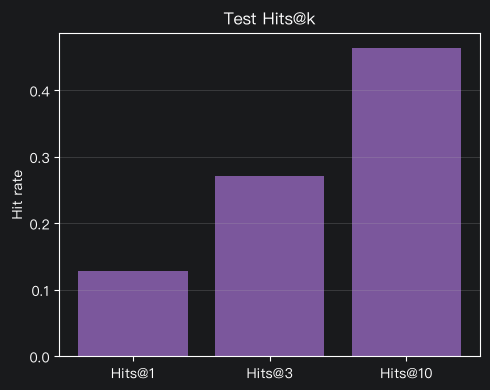

In [17]:
summary = pd.DataFrame({
    "metric": ["Test AUROC", "Test AP", "MRR", "Hits@1", "Hits@3", "Hits@10"],
    "value": [test_auc, test_ap, ranking["MRR"], ranking["Hits@1"], ranking["Hits@3"], ranking["Hits@10"]],
})
display(summary)

fig, ax = plt.subplots(figsize=(5, 4))
ks = ["Hits@1", "Hits@3", "Hits@10"]
ax.bar(ks, [ranking[k] for k in ks], color="tab:purple", alpha=0.8)
ax.set_ylabel("Hit rate")
ax.set_title("Test Hits@k")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("../outputs/hits_at_k.png", dpi=150)
plt.show()